# 06_02 — Lag study: laser scope vs charge

Does the laser scope signal correlate better with the charge (`BCM_GUN`) when it is **shifted in time** by up to ±5 shots?

Two per-shot laser numbers, as in notebook 03 (background = mean before 5 ns, pulse train = 5.6–39.8 ns):
- **matched filter** `laser_amp` — projection on the mean pulse train (1.0 = average shot)
- **integral** `laser_int` — sum of the background-subtracted trace over the train [V·ns]

Shots where the scope **froze** (identical trace to the previous shot, ~23%) are left out.

- **Convention:** rows as recorded. For lag *L* we correlate `laser[i + L]` with `BCM_GUN[i]`;
  a peak at **L = +1** means the laser value that belongs to shot *i* is stored one row later.
- **overall** r uses the raw values (includes the slow drift); **shot-to-shot** r removes a 51-shot rolling mean first.
- Noise level for ~1600 shots: |r| ≲ 0.075.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
files = sorted(DATA_DIR.glob("chunk_*.h5"))

LAGS = np.arange(-5, 6)
TRAIN = (5.6, 39.8)  # ns
SERIES = ["#2a78d6", "#eb6834"]  # overall, shot-to-shot
MUTED = "#8a8985"


def load(key):
    return np.concatenate([h5py.File(path, "r")[key][:] for path in files])


signal = load("laser_scope/signal")
t = h5py.File(files[0], "r")["laser_scope/times"][0]
charge = pd.Series(load("BCM_GUN"), name="BCM_GUN")

In [2]:
clean = signal - signal[:, t < 5].mean(axis=1, keepdims=True)
in_train = (t > TRAIN[0]) & (t < TRAIN[1])
template = clean.mean(axis=0) * in_train
frozen = np.r_[False, np.all(signal[1:] == signal[:-1], axis=1)]

laser = pd.DataFrame({
    "matched filter": clean @ template / (template @ template),
    "integral": clean[:, in_train].sum(axis=1) * (t[1] - t[0]),
})
laser[frozen] = np.nan  # frozen shots are skipped in every correlation
print(f"{len(laser)} shots, {frozen.sum()} frozen ({frozen.mean():.0%}) left out")

2100 shots, 483 frozen (23%) left out


In [3]:
def detrend(x, k=51):
    return x - x.rolling(k, center=True, min_periods=1).mean()


r = {
    method: pd.DataFrame({
        "overall": [charge.corr(laser[method].shift(-lag)) for lag in LAGS],
        "shot-to-shot": [detrend(charge).corr(detrend(laser[method]).shift(-lag)) for lag in LAGS],
    }, index=pd.Index(LAGS, name="lag"))
    for method in laser.columns
}
pd.concat(r, axis=1).round(3).T

lag                             -5     -4     -3     -2     -1      0      1  \
matched filter overall       0.566  0.567  0.577  0.608  0.615  0.657  0.775   
               shot-to-shot -0.022 -0.034 -0.007  0.059  0.089  0.186  0.485   
integral       overall       0.492  0.484  0.489  0.518  0.535  0.563  0.675   
               shot-to-shot -0.003 -0.033 -0.020  0.032  0.079  0.134  0.371   

lag                              2      3      4      5  
matched filter overall       0.602  0.598  0.600  0.575  
               shot-to-shot  0.050  0.035  0.037 -0.003  
integral       overall       0.513  0.501  0.510  0.496  
               shot-to-shot  0.027  0.001  0.019  0.006

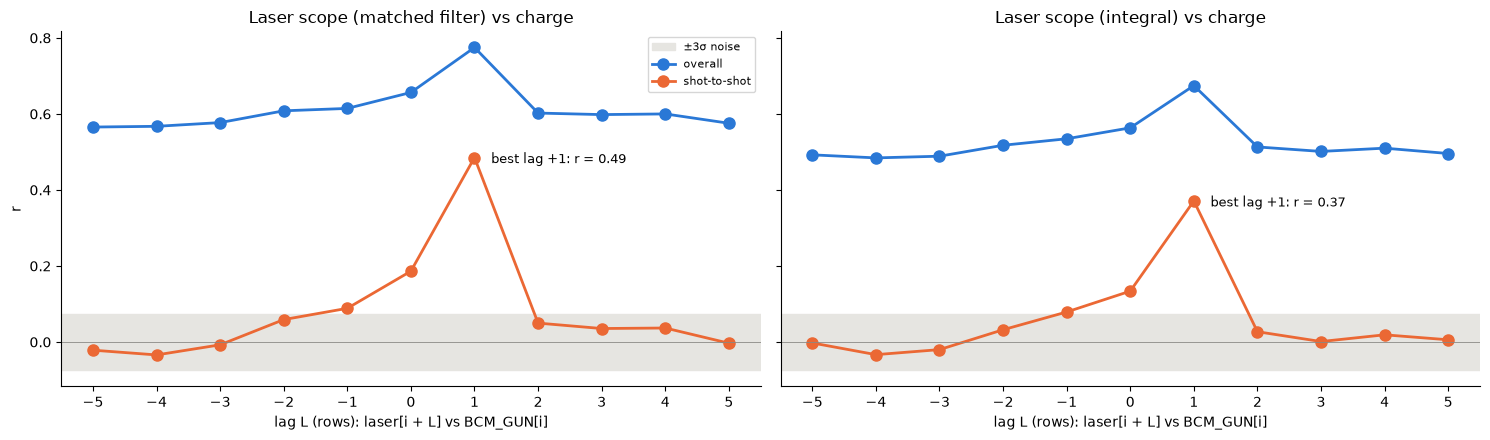

In [4]:
noise = 3 / np.sqrt(len(laser) - frozen.sum())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (method, table) in zip(axes, r.items()):
    best = table["shot-to-shot"].abs().idxmax()
    ax.axhspan(-noise, noise, color="#e6e5e1", label="±3σ noise")
    for color, col in zip(SERIES, table.columns):
        ax.plot(LAGS, table[col], "o-", color=color, lw=2, ms=8, label=col)
    ax.axhline(0, color=MUTED, lw=0.6)
    ax.annotate(f"best lag {best:+d}: r = {table.loc[best, 'shot-to-shot']:.2f}", (best, table.loc[best, "shot-to-shot"]),
                xytext=(12, -4), textcoords="offset points", fontsize=9)
    ax.set(xticks=LAGS, xlabel="lag L (rows): laser[i + L] vs BCM_GUN[i]", title=f"Laser scope ({method}) vs charge")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[0].set_ylabel("r")
axes[0].legend(fontsize=8)
fig.tight_layout()

## Scatter: no shift vs best shift (matched filter)

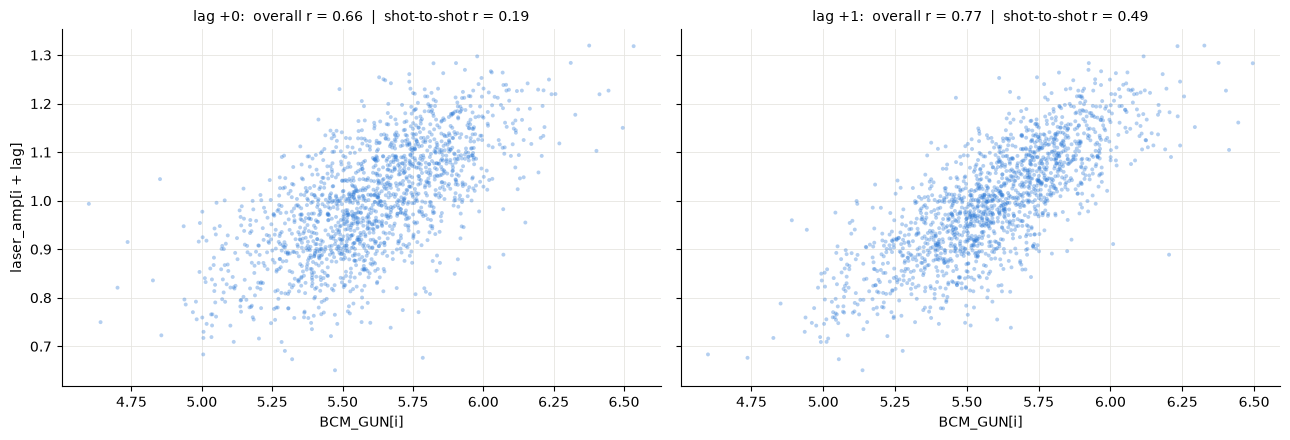

In [5]:
table = r["matched filter"]
best = table["shot-to-shot"].abs().idxmax()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, lag in zip(axes, [0, best]):
    ax.scatter(charge, laser["matched filter"].shift(-lag), s=8, color=SERIES[0], alpha=0.35, edgecolors="none")
    ax.set(xlabel="BCM_GUN[i]", title=f"lag {lag:+d}:  overall r = {table.loc[lag, 'overall']:.2f}  |  "
                                        f"shot-to-shot r = {table.loc[lag, 'shot-to-shot']:.2f}")
    ax.title.set_fontsize(10)
    ax.grid(color="#e6e5e1", lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[0].set_ylabel("laser_amp[i + lag]")
fig.tight_layout()